<a href="https://www.kaggle.com/code/lalit7881/global-book-bestseller-trends-eda-100?scriptVersionId=364125814" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mnkaggler/international-bestselling-books-market-trends/international_bestsellers_dataset.csv


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/mnkaggler/international-bestselling-books-market-trends/international_bestsellers_dataset.csv")

In [3]:
df.head()

,date,country,rank,title,author,nationality,gender,entry_id,publisher,publication_country
0,2022-12-01,France,1,The Wizard of the Kremlin,Giuliano da Empoli,Italy,m,2022-02Bulgaria591,Éditions Gallimard,France
1,2022-12-01,Germany,1,Facial Expressions,Sebastian Fitzek,Germany,m,2022-02Bulgaria601,Droemer Knaur,Germany
2,2022-12-01,Italy,1,The House of Lights,Donato Carrisi,Italy,m,2022-02Bulgaria611,Longanesi,Italy
3,2022-12-01,Spain,1,Waiting for the Deluge,Dolores Redondo,Spain,w,2022-02Bulgaria621,Destino,Spain
4,2022-12-01,Egypt,1,Orfanelli Hall,Achraf El Achmawi,Egypt,m,2022-02Bulgaria631,The Egyptian Lebanese House,Egypt


In [4]:
df.tail()

,date,country,rank,title,author,nationality,gender,entry_id,publisher,publication_country
7904,2013-06-01,Germany,10,The Golden Shore,Iny Lorentz,Germany,m; w,2013-06Germany10,Droemer Knaur,Germany
7905,2013-06-01,Italy,10,I Watch You,Irene Cao,Italy,w,2013-06Italy10,Rizzoli,Italy
7906,2013-06-01,South Korea,10,The Art of Thinking Clearly,Rolf Dobelli,Switzerland,m,2013-06South Korea10,Hanser,Germany
7907,2013-06-01,Spain,10,The Barefoot Queen,Ildefonso Falcones,Spain,m,2013-06Spain10,Grijalbo,Spain
7908,2013-06-01,United States,10,Best Kept Secret,Jeffrey Archer,United Kingdom,m,2013-06United States10,Macmillan,United Kingdom


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7909 entries, 0 to 7908
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   date                 7909 non-null   object
 1   country              7909 non-null   object
 2   rank                 7909 non-null   int64 
 3   title                7909 non-null   object
 4   author               7909 non-null   object
 5   nationality          7899 non-null   object
 6   gender               7899 non-null   object
 7   entry_id             7909 non-null   object
 8   publisher            7907 non-null   object
 9   publication_country  7909 non-null   object
dtypes: int64(1), object(9)
memory usage: 618.0+ KB


In [6]:
df.describe()

,rank
count,7909.000000
mean,5.499431
std,2.872199
min,1.000000
25%,3.000000
50%,5.000000
75%,8.000000
max,10.000000


In [7]:
df.isnull().sum()

date                    0
country                 0
rank                    0
title                   0
author                  0
nationality            10
gender                 10
entry_id                0
publisher               2
publication_country     0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

date                   object
country                object
rank                    int64
title                  object
author                 object
nationality            object
gender                 object
entry_id               object
publisher              object
publication_country    object
dtype: object

In [10]:
df.shape

(7909, 10)

In [11]:
df.columns

Index(['date', 'country', 'rank', 'title', 'author', 'nationality', 'gender',
       'entry_id', 'publisher', 'publication_country'],
      dtype='object')

In [12]:
df.nunique()

date                    114
country                  45
rank                     10
title                  3754
author                 1850
nationality             160
gender                   16
entry_id               7909
publisher               750
publication_country      52
dtype: int64

## EDA

In [13]:


# Visualization settings
sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9

# ==========================================
# 2. LOAD DATASET
# ==========================================

# If df is already available, use it directly.
# Otherwise:
# df = pd.read_csv('/kaggle/input/dataset-name/file.csv')

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nFirst 5 Records:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe(include='all'))

Dataset Shape: (7909, 10)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7909 entries, 0 to 7908
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   date                 7909 non-null   object
 1   country              7909 non-null   object
 2   rank                 7909 non-null   int64 
 3   title                7909 non-null   object
 4   author               7909 non-null   object
 5   nationality          7899 non-null   object
 6   gender               7899 non-null   object
 7   entry_id             7909 non-null   object
 8   publisher            7907 non-null   object
 9   publication_country  7909 non-null   object
dtypes: int64(1), object(9)
memory usage: 618.0+ KB
None

First 5 Records:


,date,country,rank,title,author,nationality,gender,entry_id,publisher,publication_country
0,2022-12-01,France,1,The Wizard of the Kremlin,Giuliano da Empoli,Italy,m,2022-02Bulgaria591,Éditions Gallimard,France
1,2022-12-01,Germany,1,Facial Expressions,Sebastian Fitzek,Germany,m,2022-02Bulgaria601,Droemer Knaur,Germany
2,2022-12-01,Italy,1,The House of Lights,Donato Carrisi,Italy,m,2022-02Bulgaria611,Longanesi,Italy
3,2022-12-01,Spain,1,Waiting for the Deluge,Dolores Redondo,Spain,w,2022-02Bulgaria621,Destino,Spain
4,2022-12-01,Egypt,1,Orfanelli Hall,Achraf El Achmawi,Egypt,m,2022-02Bulgaria631,The Egyptian Lebanese House,Egypt



Missing Values:
date                    0
country                 0
rank                    0
title                   0
author                  0
nationality            10
gender                 10
entry_id                0
publisher               2
publication_country     0
dtype: int64

Statistical Summary:


,date,country,rank,title,author,nationality,gender,entry_id,publisher,publication_country
count,7909,7909,7909.000000,7909,7909,7899,7899,7909,7907,7909
unique,114,45,NaN,3754,1850,160,16,7909,750,52
top,2022-12-01,Germany,NaN,The Girl on the Train,Elena Ferrante,United States,m,2013-06United States10,Doubleday,United States
freq,70,1140,NaN,62,120,1886,4230,1,278,2301
mean,NaN,NaN,5.499431,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,2.872199,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,3.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,5.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,8.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


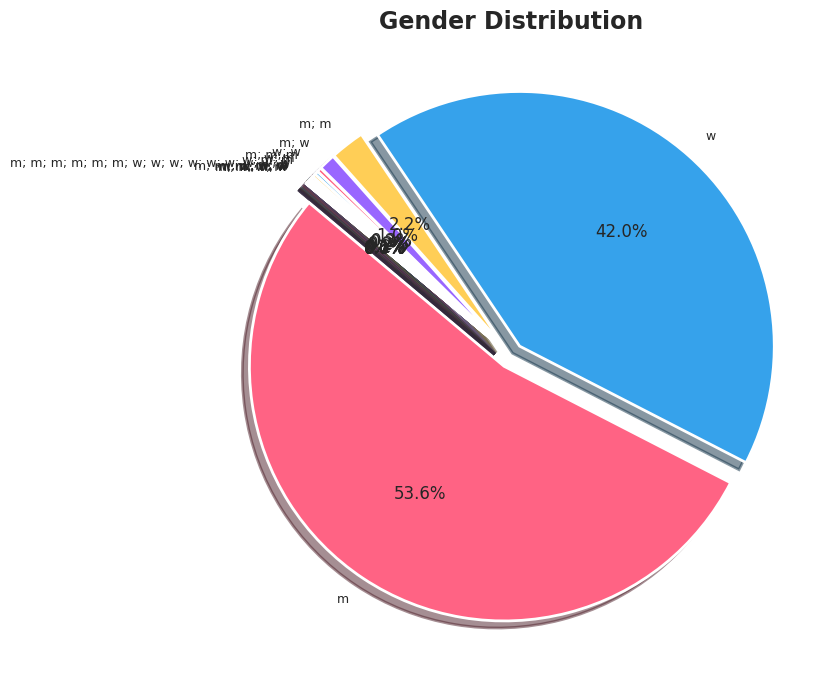

In [14]:
plt.figure(figsize=(9, 7))

gender_counts = df['gender'].value_counts()

colors = ['#FF6384', '#36A2EB', '#FFCE56', '#9966FF']

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors[:len(gender_counts)],
    explode=[0.05] * len(gender_counts),
    shadow=True,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

plt.title("Gender Distribution",
          fontsize=17, fontweight='bold')

plt.tight_layout()
plt.show()

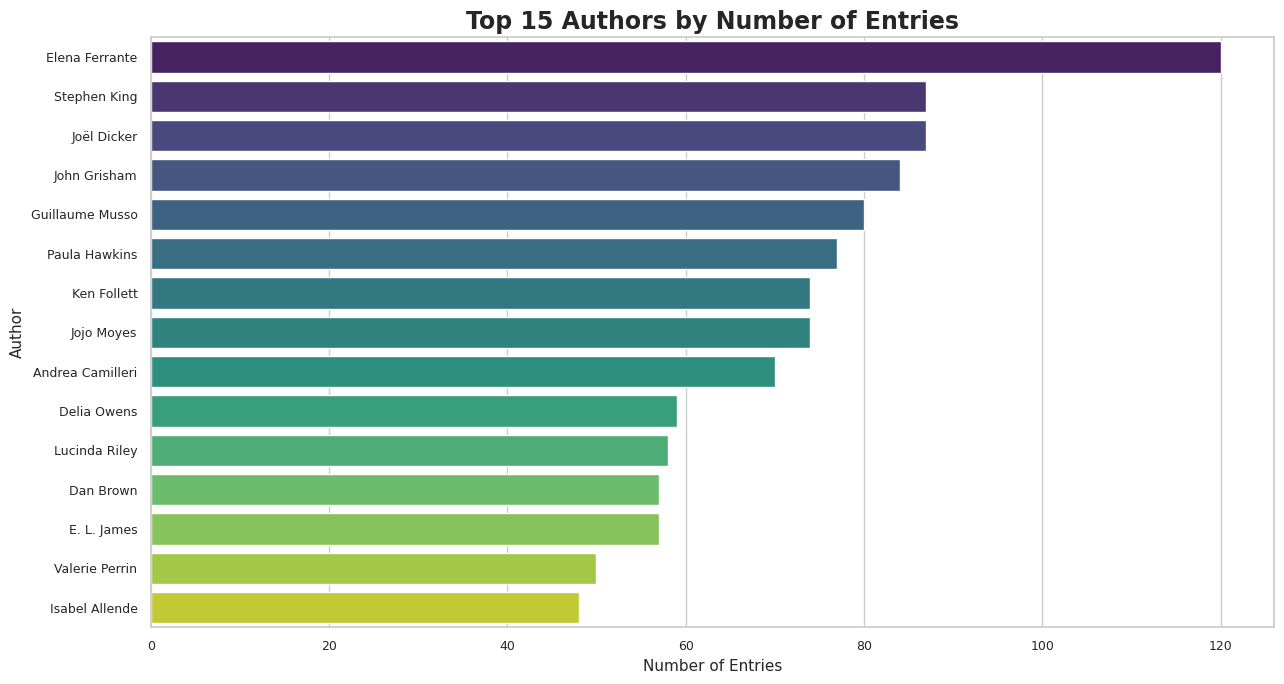

In [15]:
plt.figure(figsize=(13, 7))

author_counts = df['author'].value_counts().head(15)

sns.barplot(
    x=author_counts.values,
    y=author_counts.index,
    hue=author_counts.index,
    palette='viridis',
    legend=False
)

plt.title("Top 15 Authors by Number of Entries",
          fontsize=17, fontweight='bold')

plt.xlabel("Number of Entries")
plt.ylabel("Author")

plt.tight_layout()
plt.show()

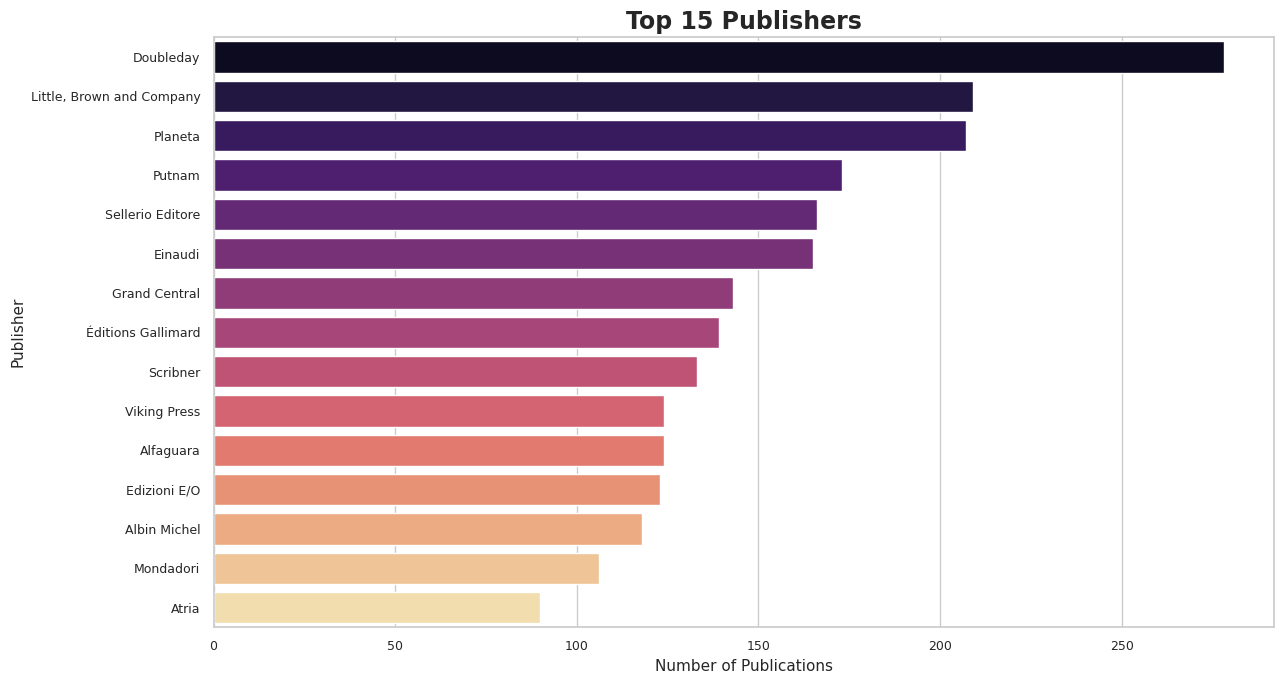

In [16]:
plt.figure(figsize=(13, 7))

publisher_counts = df['publisher'].value_counts().head(15)

sns.barplot(
    x=publisher_counts.values,
    y=publisher_counts.index,
    hue=publisher_counts.index,
    palette='magma',
    legend=False
)

plt.title("Top 15 Publishers",
          fontsize=17, fontweight='bold')

plt.xlabel("Number of Publications")
plt.ylabel("Publisher")

plt.tight_layout()
plt.show()

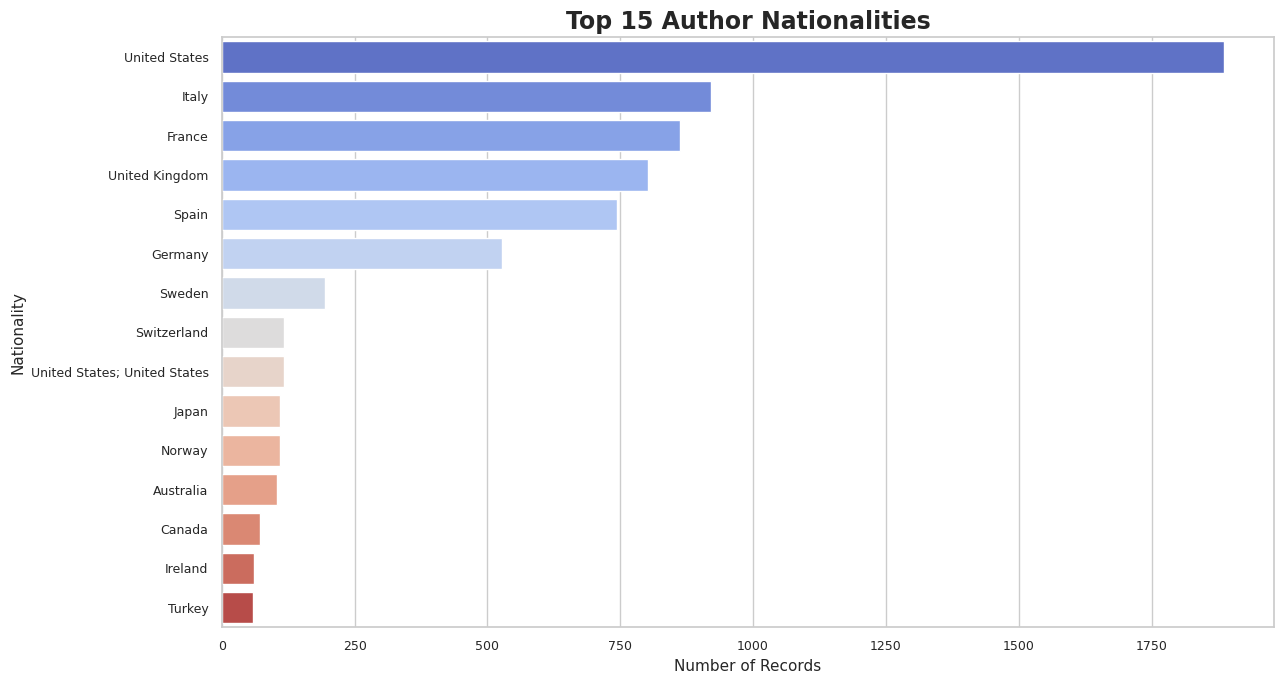

In [17]:
plt.figure(figsize=(13, 7))

nationality_counts = df['nationality'].value_counts().head(15)

sns.barplot(
    x=nationality_counts.values,
    y=nationality_counts.index,
    hue=nationality_counts.index,
    palette='coolwarm',
    legend=False
)

plt.title("Top 15 Author Nationalities",
          fontsize=17, fontweight='bold')

plt.xlabel("Number of Records")
plt.ylabel("Nationality")

plt.tight_layout()
plt.show()

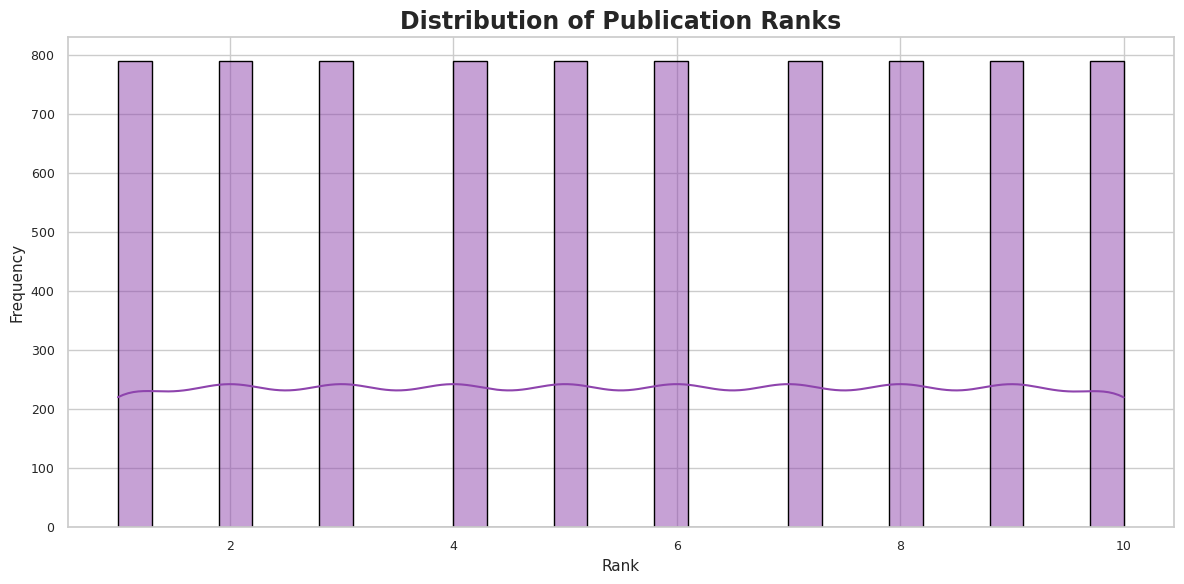

In [18]:
plt.figure(figsize=(12, 6))

rank_data = df['rank'].dropna()

sns.histplot(
    rank_data,
    bins=30,
    kde=True,
    color='#8E44AD',
    edgecolor='black'
)

plt.title("Distribution of Publication Ranks",
          fontsize=17, fontweight='bold')

plt.xlabel("Rank")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

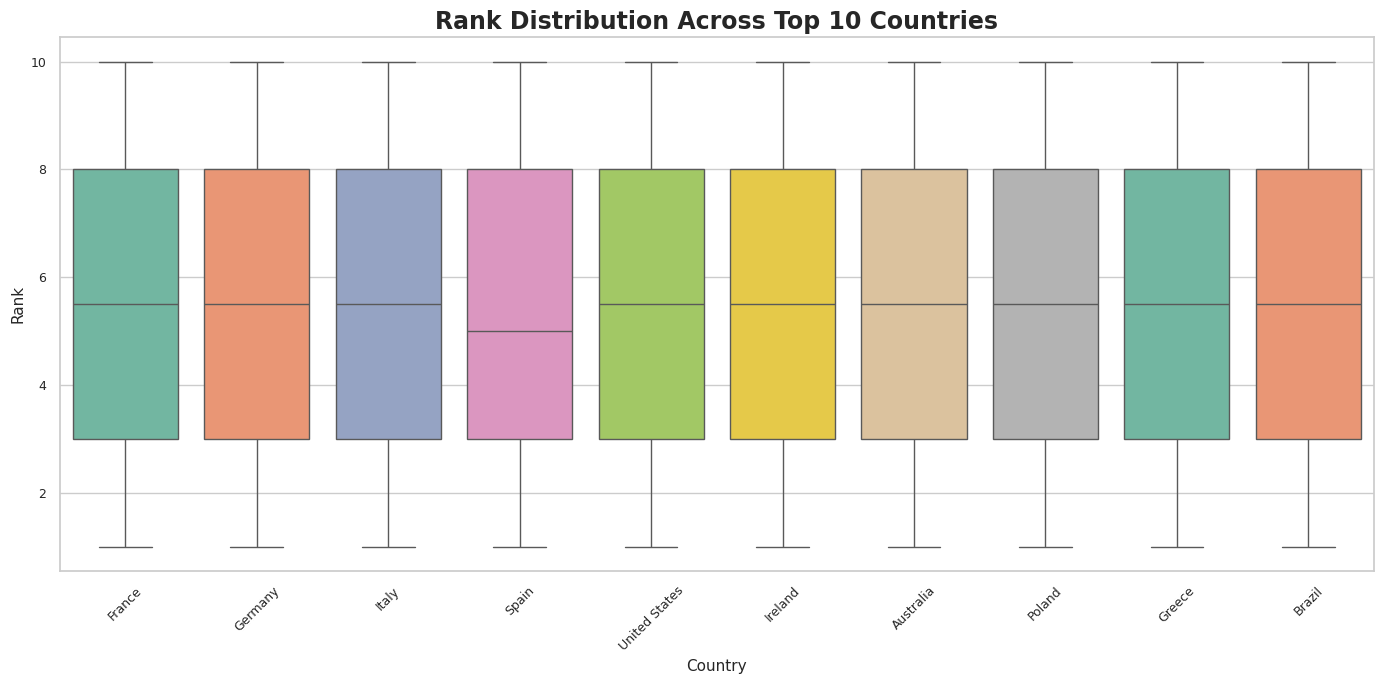

In [19]:
plt.figure(figsize=(14, 7))

top_countries = df['country'].value_counts().head(10).index

rank_country_df = df[df['country'].isin(top_countries)]

sns.boxplot(
    data=rank_country_df,
    x='country',
    y='rank',
    hue='country',
    palette='Set2',
    legend=False
)

plt.title("Rank Distribution Across Top 10 Countries",
          fontsize=17, fontweight='bold')

plt.xlabel("Country")
plt.ylabel("Rank")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

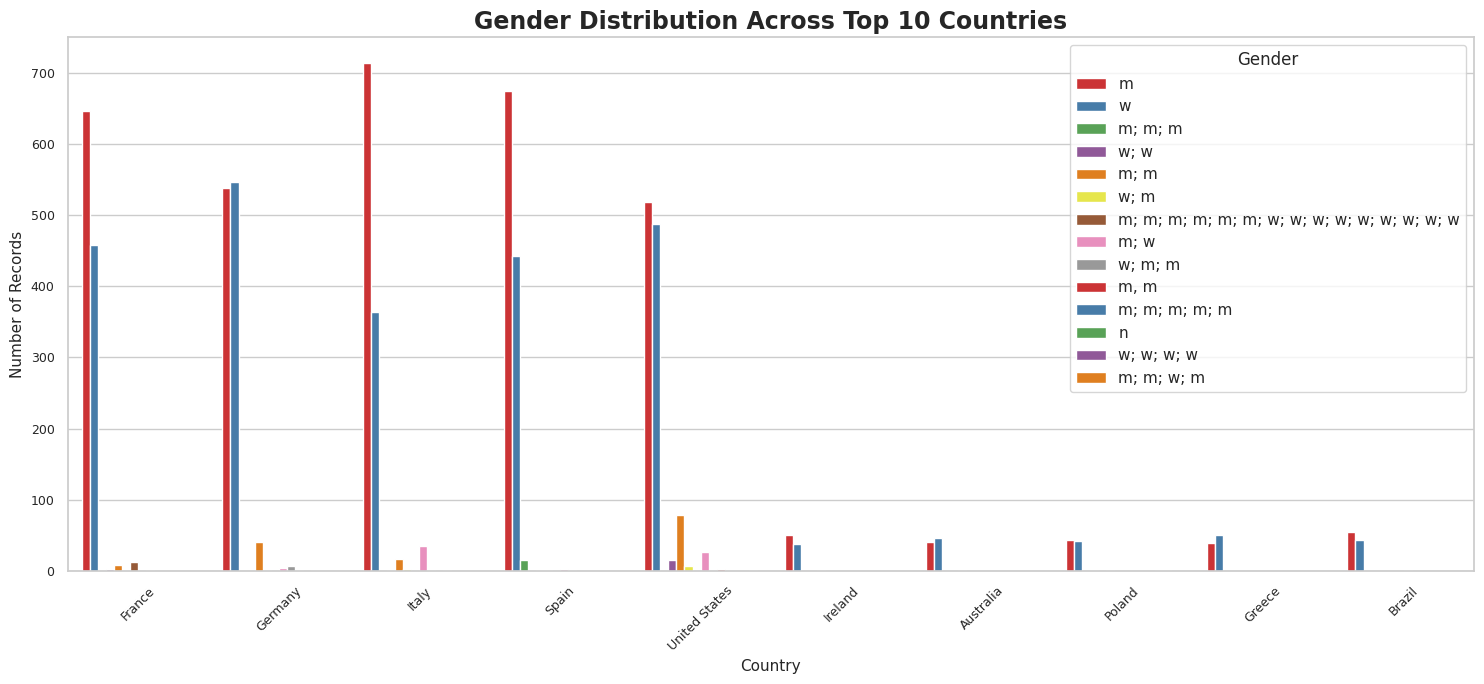

In [20]:
plt.figure(figsize=(15, 7))

top_countries = df['country'].value_counts().head(10).index

gender_country_df = df[
    df['country'].isin(top_countries)
]

sns.countplot(
    data=gender_country_df,
    x='country',
    hue='gender',
    palette='Set1'
)

plt.title("Gender Distribution Across Top 10 Countries",
          fontsize=17, fontweight='bold')

plt.xlabel("Country")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)
plt.legend(title="Gender")

plt.tight_layout()
plt.show()

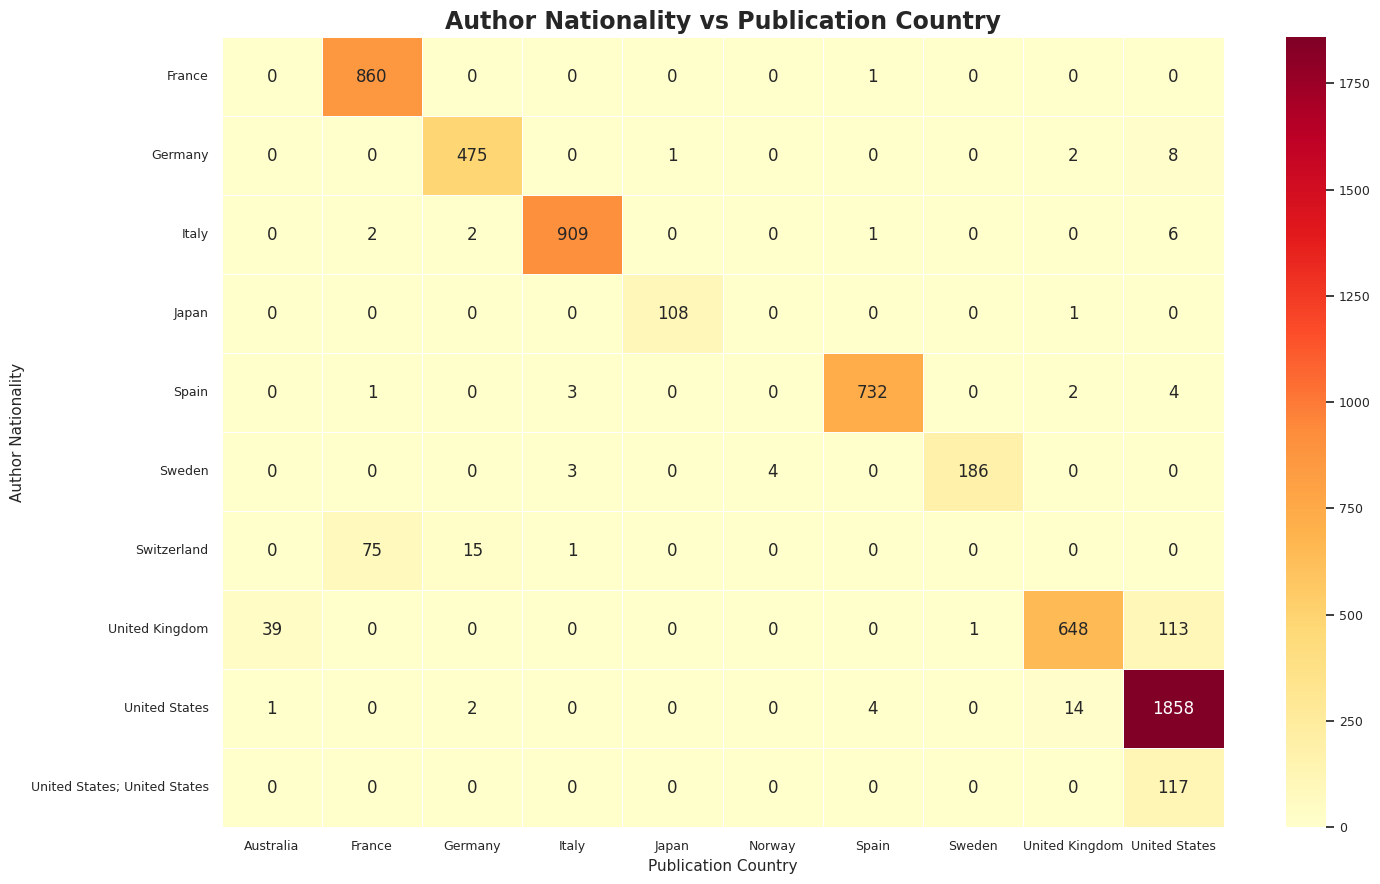

In [21]:
plt.figure(figsize=(15, 9))

top_nationalities = df['nationality'].value_counts().head(10).index
top_publication_countries = (
    df['publication_country'].value_counts().head(10).index
)

heatmap_df = df[
    df['nationality'].isin(top_nationalities) &
    df['publication_country'].isin(top_publication_countries)
]

pivot_table = pd.crosstab(
    heatmap_df['nationality'],
    heatmap_df['publication_country']
)

sns.heatmap(
    pivot_table,
    annot=True,
    fmt='d',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar=True
)

plt.title("Author Nationality vs Publication Country",
          fontsize=17, fontweight='bold')

plt.xlabel("Publication Country")
plt.ylabel("Author Nationality")

plt.tight_layout()
plt.show()

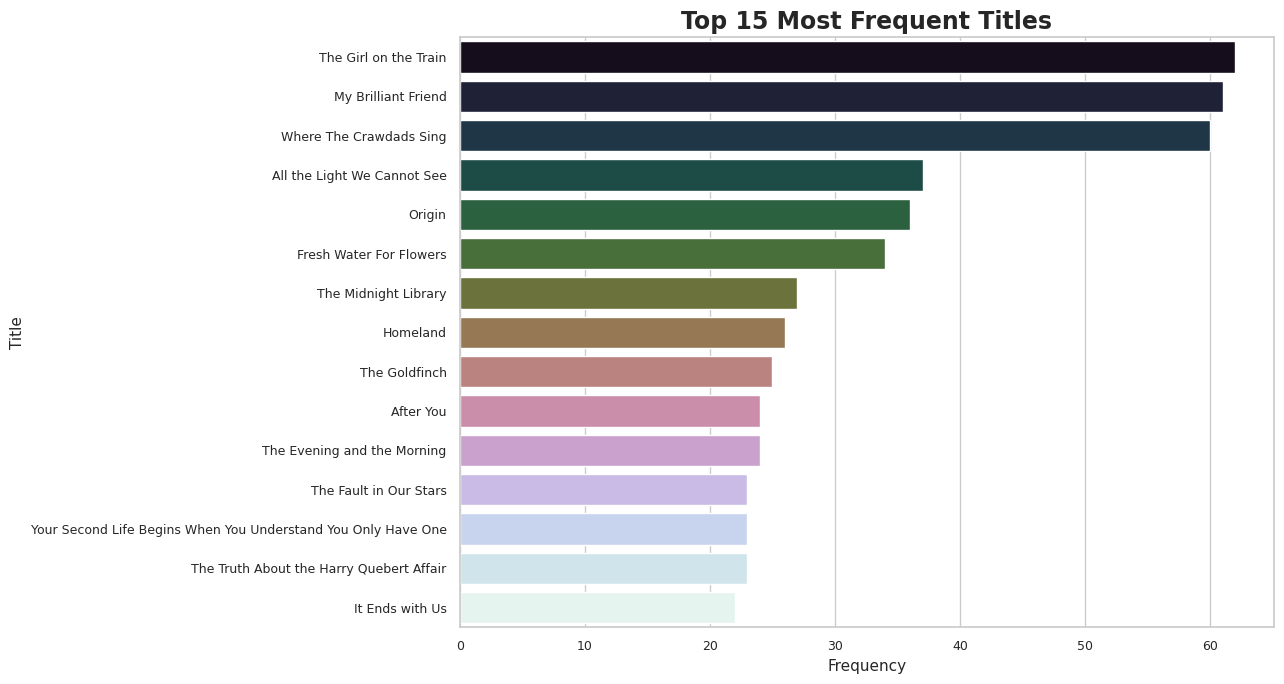

In [22]:
plt.figure(figsize=(13, 7))

title_counts = df['title'].value_counts().head(15)

sns.barplot(
    x=title_counts.values,
    y=title_counts.index,
    hue=title_counts.index,
    palette='cubehelix',
    legend=False
)

plt.title("Top 15 Most Frequent Titles",
          fontsize=17, fontweight='bold')

plt.xlabel("Frequency")
plt.ylabel("Title")

plt.tight_layout()
plt.show()

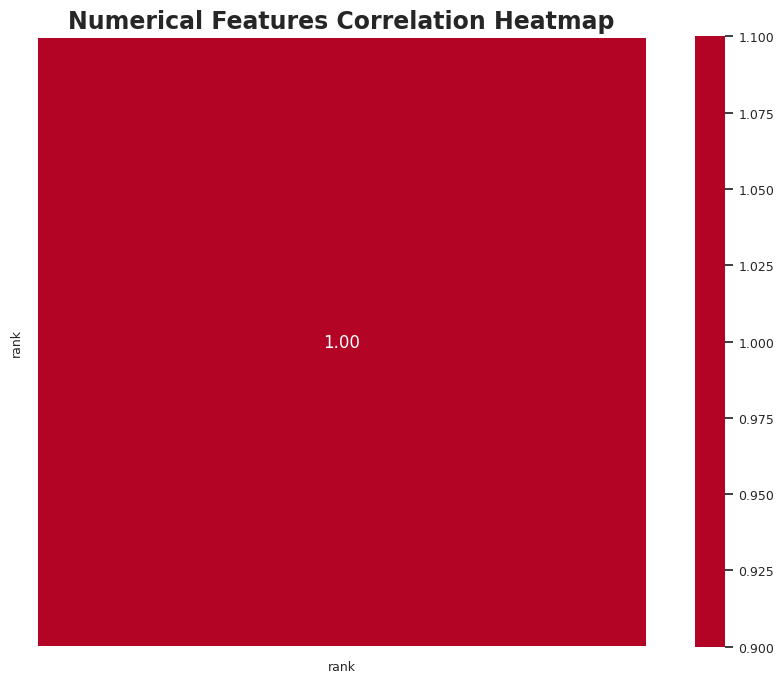

In [23]:
plt.figure(figsize=(10, 7))

numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=1,
    square=True,
    center=0
)

plt.title("Numerical Features Correlation Heatmap",
          fontsize=17, fontweight='bold')

plt.tight_layout()
plt.show()

In [24]:
# ==========================================
# FINAL DATASET INSIGHTS
# ==========================================

print("=" * 60)
print("           DATASET ANALYSIS SUMMARY")
print("=" * 60)

print("\nTotal Records:", len(df))

print("\nUnique Countries:", df['country'].nunique())

print("\nUnique Authors:", df['author'].nunique())

print("\nUnique Publishers:", df['publisher'].nunique())

print("\nUnique Titles:", df['title'].nunique())

print("\nUnique Nationalities:", df['nationality'].nunique())

print("\nUnique Publication Countries:",
      df['publication_country'].nunique())

print("\nDate Range:")
print("Start Date:", df['date'].min())
print("End Date:", df['date'].max())

print("\nTop 5 Countries:")
print(df['country'].value_counts().head(5))

print("\nTop 5 Authors:")
print(df['author'].value_counts().head(5))

print("\nTop 5 Publishers:")
print(df['publisher'].value_counts().head(5))

print("\nGender Distribution:")
print(df['gender'].value_counts())

print("\nAverage Rank:", df['rank'].mean())

print("\n" + "=" * 60)
print("          ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 60)

           DATASET ANALYSIS SUMMARY

Total Records: 7909

Unique Countries: 45

Unique Authors: 1850

Unique Publishers: 750

Unique Titles: 3754

Unique Nationalities: 160

Unique Publication Countries: 52

Date Range:
Start Date: 2013-06-01
End Date: 2022-12-01

Top 5 Countries:
country
Germany          1140
Italy            1140
United States    1140
Spain            1139
France           1130
Name: count, dtype: int64

Top 5 Authors:
author
Elena Ferrante     120
Stephen King        87
Joël Dicker         87
John Grisham        84
Guillaume Musso     80
Name: count, dtype: int64

Top 5 Publishers:
publisher
Doubleday                    278
Little, Brown and Company    209
Planeta                      207
Putnam                       173
Sellerio Editore             166
Name: count, dtype: int64

Gender Distribution:
gender
m                                              4230
w                                              3316
m; m                                            171
m; w 

## Feature engineering

In [25]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning Algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [26]:
# ==========================================
# 2. DATA PREPROCESSING
# ==========================================

df_ml = df.copy()

# Remove duplicate records
df_ml.drop_duplicates(inplace=True)

# Convert date column
df_ml['date'] = pd.to_datetime(
    df_ml['date'],
    errors='coerce'
)

# Extract date features
df_ml['year'] = df_ml['date'].dt.year
df_ml['month'] = df_ml['date'].dt.month
df_ml['day'] = df_ml['date'].dt.day

# Remove original date and ID
df_ml.drop(
    columns=['date', 'entry_id'],
    inplace=True,
    errors='ignore'
)

# Convert rank to numeric
df_ml['rank'] = pd.to_numeric(
    df_ml['rank'],
    errors='coerce'
)

# Handle missing categorical values
categorical_cols = [
    'country',
    'title',
    'author',
    'nationality',
    'gender',
    'publisher',
    'publication_country'
]

for col in categorical_cols:
    df_ml[col] = (
        df_ml[col]
        .fillna('Unknown')
        .astype(str)
        .str.strip()
    )

# Remove rows with completely missing target candidates
df_ml = df_ml.dropna(how='all')

print("Preprocessing completed!")
print("Dataset Shape:", df_ml.shape)

display(df_ml.head())

Preprocessing completed!
Dataset Shape: (7909, 11)


,country,rank,title,author,nationality,gender,publisher,publication_country,year,month,day
0,France,1,The Wizard of the Kremlin,Giuliano da Empoli,Italy,m,Éditions Gallimard,France,2022,12,1
1,Germany,1,Facial Expressions,Sebastian Fitzek,Germany,m,Droemer Knaur,Germany,2022,12,1
2,Italy,1,The House of Lights,Donato Carrisi,Italy,m,Longanesi,Italy,2022,12,1
3,Spain,1,Waiting for the Deluge,Dolores Redondo,Spain,w,Destino,Spain,2022,12,1
4,Egypt,1,Orfanelli Hall,Achraf El Achmawi,Egypt,m,The Egyptian Lebanese House,Egypt,2022,12,1


Target Distribution:
target
1    7909
Name: count, dtype: int64

Target Percentage:
target
1    100.0
Name: proportion, dtype: float64


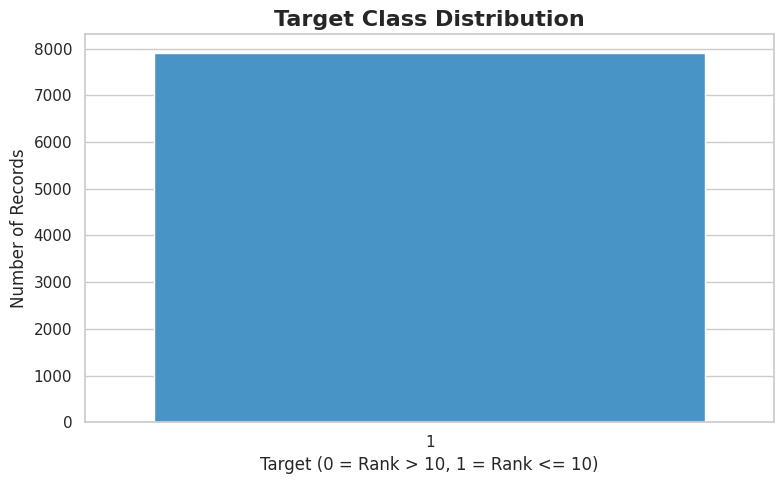

In [27]:
# ==========================================
# 3. TARGET VARIABLE CREATION
# ==========================================

df_ml = df_ml.dropna(subset=['rank'])

# Create binary target
df_ml['target'] = (
    df_ml['rank'] <= 10
).astype(int)

print("Target Distribution:")
print(df_ml['target'].value_counts())

print("\nTarget Percentage:")
print(
    df_ml['target']
    .value_counts(normalize=True) * 100
)

# Visualize target distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_ml,
    x='target',
    hue='target',
    palette=['#3498DB', '#E74C3C'],
    legend=False
)

plt.title(
    "Target Class Distribution",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Target (0 = Rank > 10, 1 = Rank <= 10)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [28]:
# ==========================================
# 4. LABEL ENCODING
# ==========================================

from sklearn.preprocessing import OrdinalEncoder

# Separate features and target
X = df_ml.drop(
    columns=['target', 'rank'],
    errors='ignore'
)

y = df_ml['target']

# Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=['object', 'string', 'category']
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

# Label encoding through OrdinalEncoder
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(
            strategy='constant',
            fill_value='Unknown'
        )),
        ('encoder', OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ))
    ]
)

# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, categorical_features),
        ('num', numerical_transformer, numerical_features)
    ]
)

print("\nLabel Encoding and preprocessing pipeline created!")

Categorical Features:
['country', 'title', 'author', 'nationality', 'gender', 'publisher', 'publication_country']

Numerical Features:
['year', 'month', 'day']

Label Encoding and preprocessing pipeline created!


In [29]:
# ==========================================
# 5. TRAIN TEST SPLITTING
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Distribution:")
print(y_train.value_counts())

print("\nTesting Distribution:")
print(y_test.value_counts())

Training Features: (6327, 10)
Testing Features: (1582, 10)

Training Target: (6327,)
Testing Target: (1582,)

Training Distribution:
target
1    6327
Name: count, dtype: int64

Testing Distribution:
target
1    1582
Name: count, dtype: int64


In [30]:
# ==========================================
# 6. MACHINE LEARNING MODELS
# ==========================================

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=10,
        random_state=42,
        class_weight='balanced'
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=150,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),

    'AdaBoost': AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Naive Bayes': GaussianNB(),

    'SVM': SVC(
        kernel='rbf',
        probability=True,
        class_weight='balanced',
        random_state=42
    ),

    'Hist Gradient Boosting': HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        random_state=42
    )
}

print("Total ML Algorithms:", len(models))

Total ML Algorithms: 10


In [31]:
# ==========================================
# 7. MODEL TRAINING AND EVALUATION
# ==========================================

results = []
trained_models = {}
roc_data = {}

for name, model in models.items():

    print("\n" + "=" * 60)
    print("Training:", name)
    print("=" * 60)

    try:

        # Create complete pipeline
        clf = Pipeline(
            steps=[
                ('preprocessor', preprocessor),
                ('classifier', model)
            ]
        )

        # Train model
        clf.fit(X_train, y_train)

        # Predictions
        y_pred = clf.predict(X_test)

        # Probability predictions
        y_prob = clf.predict_proba(X_test)[:, 1]

        # Calculate metrics
        accuracy = accuracy_score(y_test, y_pred)

        precision = precision_score(
            y_test, y_pred, zero_division=0
        )

        recall = recall_score(
            y_test, y_pred, zero_division=0
        )

        f1 = f1_score(
            y_test, y_pred, zero_division=0
        )

        auc_score = roc_auc_score(y_test, y_prob)

        # Store results
        results.append({
            'Model': name,
            'Accuracy': accuracy * 100,
            'Precision': precision * 100,
            'Recall': recall * 100,
            'F1 Score': f1 * 100,
            'ROC AUC': auc_score
        })

        trained_models[name] = clf

        # ROC curve values
        fpr, tpr, thresholds = roc_curve(
            y_test, y_prob
        )

        roc_data[name] = {
            'fpr': fpr,
            'tpr': tpr,
            'auc': auc_score
        }

        print("Accuracy :", round(accuracy * 100, 2), "%")
        print("Precision:", round(precision * 100, 2), "%")
        print("Recall   :", round(recall * 100, 2), "%")
        print("F1 Score :", round(f1 * 100, 2), "%")
        print("ROC AUC  :", round(auc_score, 4))

    except Exception as e:
        print("Model failed:", name)
        print("Error:", str(e))

results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")

display(
    results_df.sort_values(
        by='ROC AUC',
        ascending=False
    ).round(3)
)


Training: Logistic Regression
Model failed: Logistic Regression
Error: This solver needs samples of at least 2 classes in the data, but the data contains only one class: np.int64(1)

Training: Decision Tree
Model failed: Decision Tree
Error: index 1 is out of bounds for axis 1 with size 1

Training: Random Forest
Model failed: Random Forest
Error: index 1 is out of bounds for axis 1 with size 1

Training: Gradient Boosting
Model failed: Gradient Boosting
Error: y contains 1 class after sample_weight trimmed classes with zero weights, while a minimum of 2 classes are required.

Training: Extra Trees
Model failed: Extra Trees
Error: index 1 is out of bounds for axis 1 with size 1

Training: AdaBoost
Model failed: AdaBoost
Error: index 1 is out of bounds for axis 1 with size 1

Training: KNN
Model failed: KNN
Error: index 1 is out of bounds for axis 1 with size 1

Training: Naive Bayes
Model failed: Naive Bayes
Error: index 1 is out of bounds for axis 1 with size 1

Training: SVM
Model f

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Hist Gradient Boosting,100.0,100.0,100.0,100.0,NaN


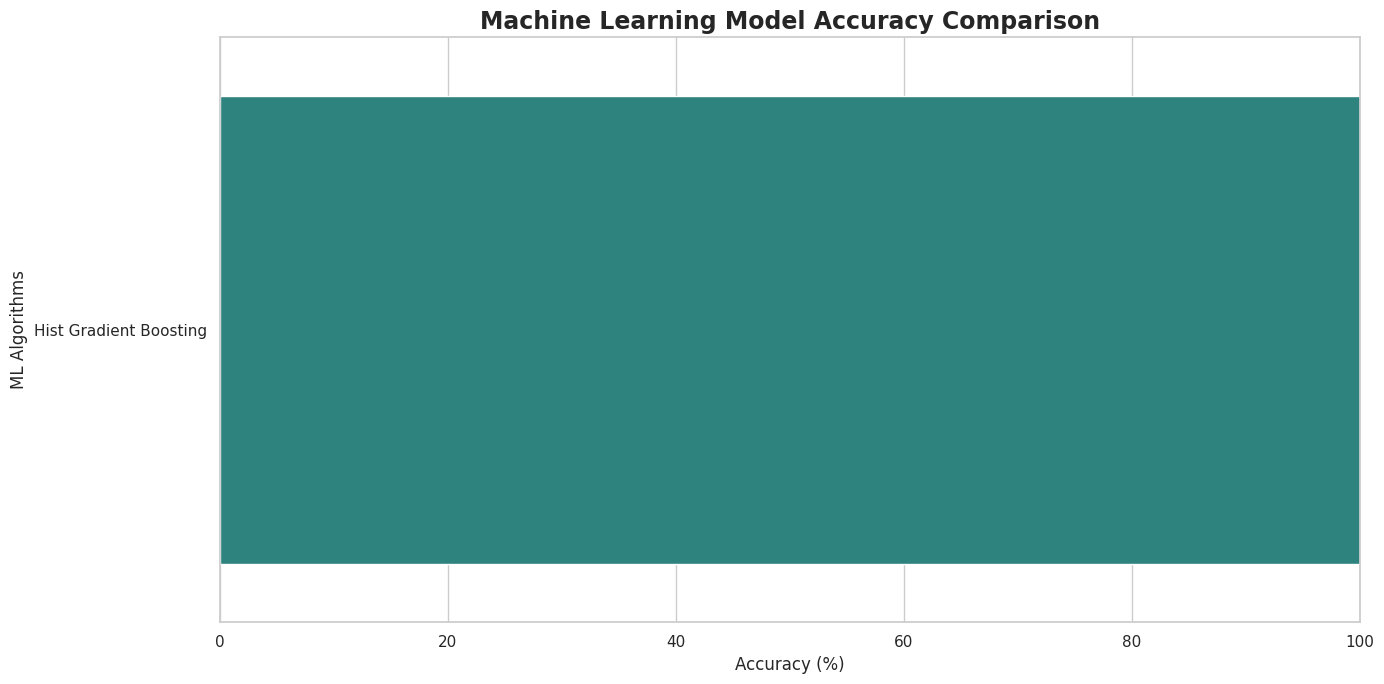

In [32]:
# ==========================================
# 8. ACCURACY COMPARISON
# ==========================================

plt.figure(figsize=(14, 7))

plot_df = results_df.sort_values(
    by='Accuracy',
    ascending=False
)

sns.barplot(
    data=plot_df,
    x='Accuracy',
    y='Model',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title(
    "Machine Learning Model Accuracy Comparison",
    fontsize=17,
    fontweight='bold'
)

plt.xlabel("Accuracy (%)")
plt.ylabel("ML Algorithms")

plt.xlim(0, 100)

plt.tight_layout()
plt.show()

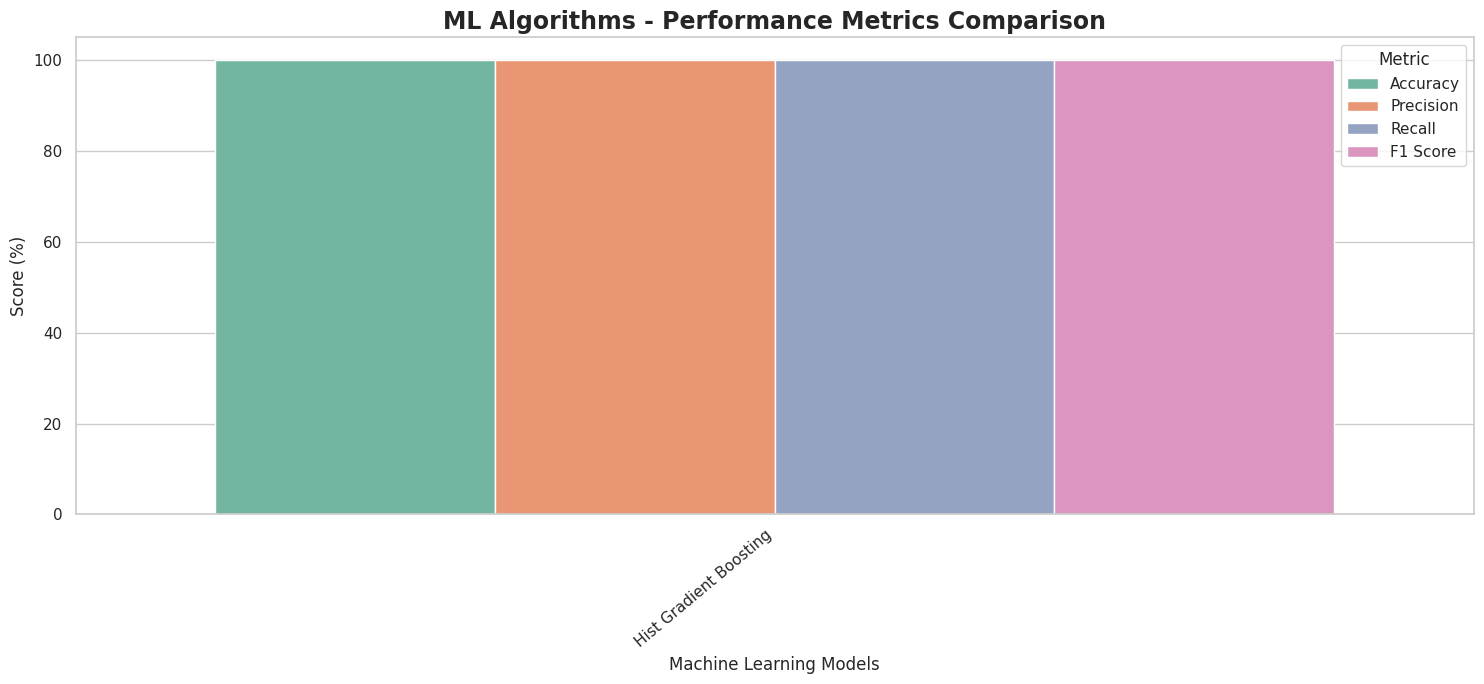

In [33]:
# ==========================================
# 9. PERFORMANCE METRICS
# ==========================================

metrics_df = results_df.melt(
    id_vars='Model',
    value_vars=[
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score'
    ],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(15, 7))

sns.barplot(
    data=metrics_df,
    x='Model',
    y='Score',
    hue='Metric',
    palette='Set2'
)

plt.title(
    "ML Algorithms - Performance Metrics Comparison",
    fontsize=17,
    fontweight='bold'
)

plt.ylabel("Score (%)")
plt.xlabel("Machine Learning Models")

plt.xticks(rotation=40, ha='right')

plt.tight_layout()
plt.show()

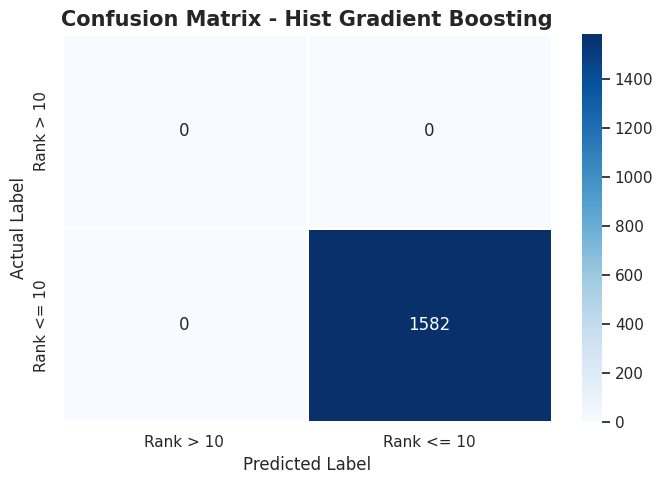

In [34]:
# ==========================================
# 10. CONFUSION MATRICES
# ==========================================

for name, clf in trained_models.items():

    y_pred = clf.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        linewidths=1,
        xticklabels=['Rank > 10', 'Rank <= 10'],
        yticklabels=['Rank > 10', 'Rank <= 10']
    )

    plt.title(
        f"Confusion Matrix - {name}",
        fontsize=15,
        fontweight='bold'
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    plt.tight_layout()
    plt.show()

## Thank you..pls upvote!!!!!!!!!